# Setting up a diffraction pattern

In this example, we initialize the pattern object via the [Pattern](#spring.Pattern) class, which enables to handle and prepare diffraction data for the reconstruction.

## Loading experimental data

Depending on the facility where the experiment has been perfomed and properties of the acquired data, there are different ways to access the raw data. **This step is in charge of the user**. 
To perform a reconstruction, the following information is strictly necessary:

- A matrix containing the measured pattern
- A matrix indicating the pixels that have to be excluded from the reconstruction (mask)
- A list containing the identification numbers of the pattern. For example, if *run* number is `123` and *pulse-id* is `456789`, the list will be ``[123,456789]``.
- The coordinates of the center position of the diffraction pattern

In the folder ``examples/data`` it is possible to find test files that already contain these  information. For example:

In [11]:
import numpy as np

data = np.load('data/example_B_1.npz')

for f in data.files:
    print(f, data[f].shape)


pattern (1054, 1024)
mask (1054, 1024)
pid (2,)
center (2,)


## Initializing the Pattern

The [Pattern](#spring.Pattern) can be now initialized with the necessary data.

In [12]:
from spring import Pattern
patt = Pattern(pattern=data['pattern'], mask=data['mask'], center=data['center'], pid=data['pid'], satvalue=3e4)

The ``satvalue`` option indicate at which value the pixels have to be considered saturated, such that they are also excluded from the reconstruction (along with those where ``mask==1``).

> **Note**  
> In priciple, saturated pixels can be included directly in the mask array. It is however reccomended to use the `satvalue` option, as those pixels are treated differently when the option ``bounds`` in the [settings](Settings) is set to a value greater than 0

The prepared pattern can be inspected via the [get](#spring.Pattern.get) method, which returns the prepared numpy array. 
Data is prepared as a square matrix. If no further option is given when the object is defined, the prepared matrix has dimensions equal to the maximum of the two dimensions of the original pattern. Missing data in the other dimension is padded with zero values


In [14]:
print(patt.get().shape)

(1054, 1054)


The prepared pattern can be visually inspected by plotting the array given by [get](#spring.Pattern.get). In the prepared pattern, masked pixels have value -1, while saturated pixels are set to -2.


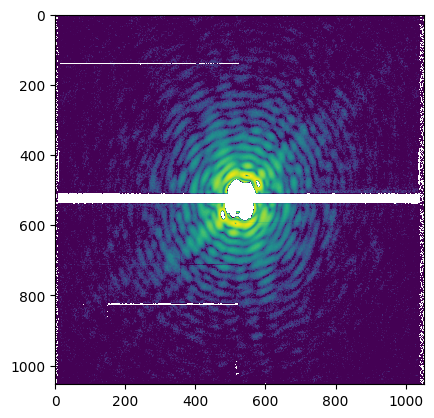

In [15]:
# Manual plot
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
plt.imshow(patt.get(), norm=LogNorm(vmin=10))
plt.show()

It is also possible to make use of a helper method, [plot()](#spring.Pattern.plot()) ,which performs directly the plotting via matplotlib. In addition, it places as a title the information contained in the `pid`.
A further helper method [plot_mask()](#spring.Pattern.plot_mask) reports the masked and saturated pixels.

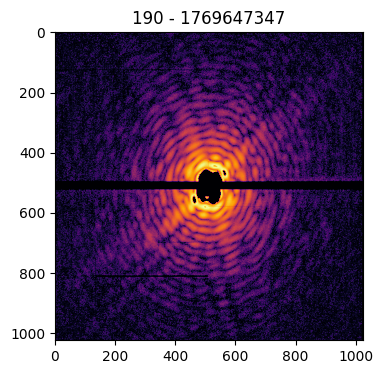

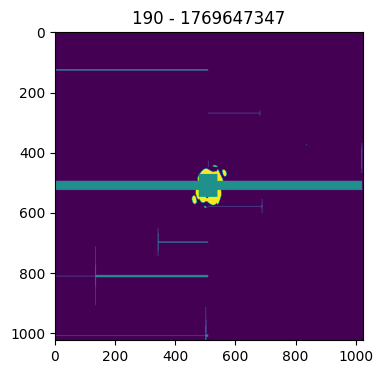

In [21]:
# Plot using helper method
patt.plot()
patt.plot_mask()

It is additionally possible to manually indicate at which size the crop operation is exectuted, by setting the ``cropsize`` parameter:

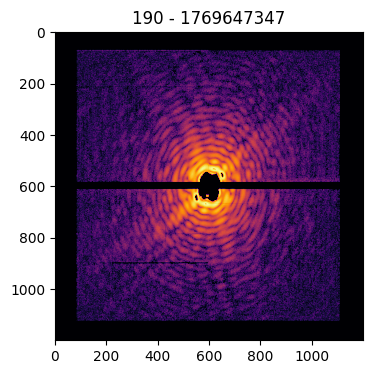

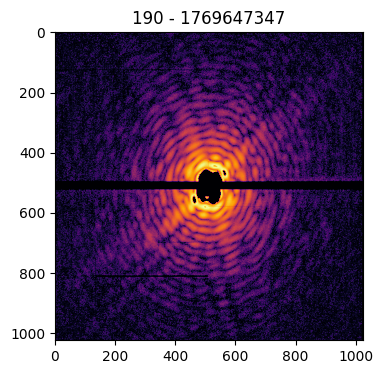

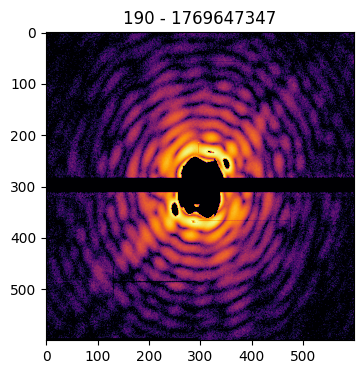

In [17]:
Pattern(pattern=data['pattern'], mask=data['mask'], center=data['center'], pid=data['pid'], satvalue=3e4, cropsize=1200).plot()
Pattern(pattern=data['pattern'], mask=data['mask'], center=data['center'], pid=data['pid'], satvalue=3e4, cropsize=1024).plot()
Pattern(pattern=data['pattern'], mask=data['mask'], center=data['center'], pid=data['pid'], satvalue=3e4, cropsize=600).plot()

Similarly, the diffraction pattern can be rescaled or binned via the ``size`` option, to set the final pattern size:

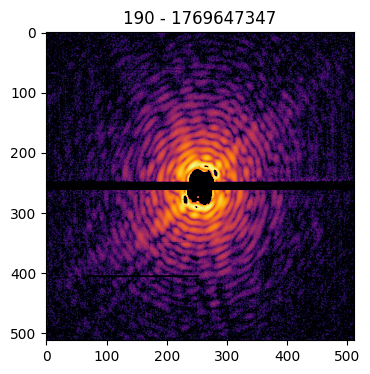

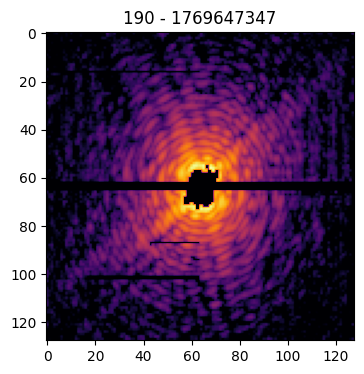

In [18]:
Pattern(pattern=data['pattern'], mask=data['mask'], center=data['center'], pid=data['pid'], satvalue=3e4, cropsize=1024, size=512).plot()
Pattern(pattern=data['pattern'], mask=data['mask'], center=data['center'], pid=data['pid'], satvalue=3e4, cropsize=1024, size=128).plot()

### Identifying the center

The imaging process requires the zero-frequency peak to be in the center of the pattern matrix. As the central data of a pattern is missing, the identification of the center position is done by looking at the symmetries in the diffraction pattern. 

To help the user in identifying the correct center, it is possible to provide the `circles` argument to the plot funcion. In this case, the indicated number of concentric circles are superimposed on the pattern image to guide the eye towards the identification of the correct coordinates of the pattern's center

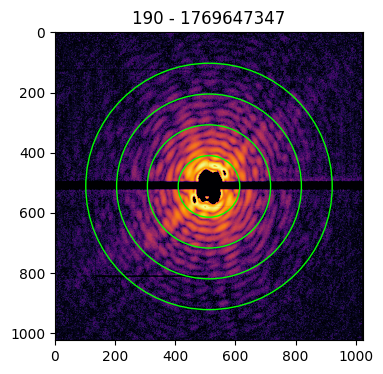

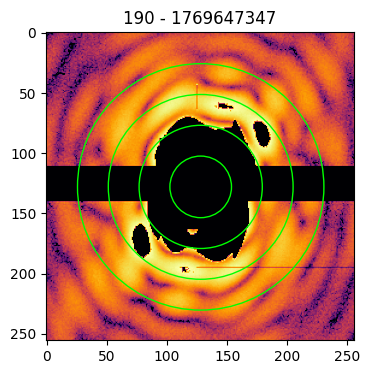

In [19]:
patt = Pattern(pattern=data['pattern'], 
               mask=data['mask'], 
               center=data['center'], 
               pid=data['pid'], 
               satvalue=3e4, cropsize=1024)
patt.plot(circles=4)
patt.plot(circles=4, cropsize=256)

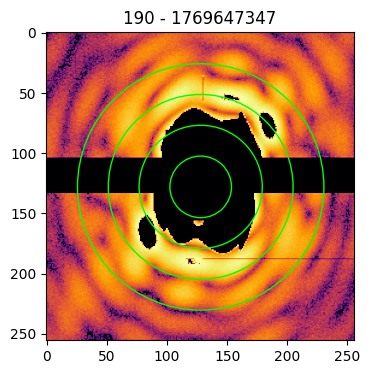

In [20]:
patt_offcenter = Pattern(pattern=data['pattern'], 
                         mask=data['mask'], 
                         center=data['center'] + np.array([7, -5]), 
                         pid=data['pid'], 
                         satvalue=3e4, cropsize=1024)
patt_offcenter.plot(circles=4, cropsize=256)